# 05 · Molecular maturity of the regenerated tissue

By 7 dpa neurons have returned to the wound and are tightly clustered there (`04_neural_spatial_organization.ipynb`). Spatial organization describes where cells are, not what genes they express, so a tissue can look rebuilt while it is still maturing. This notebook asks whether the 7 dpa wound tissue also matches the uninjured tissue at the molecular level.

**Two possible states**
- **Restored.** The 7 dpa wound expresses the same genes as the same region at 0 hpa (the head and tail ends before any wound response). Most genes that mark the 7 dpa wound should also mark the 0 hpa region, and the few that do not should not belong to any particular function.
- **Still regenerating.** Part of the 7 dpa wound signature is new, absent at 0 hpa, and enriched for active regeneration programs such as cell division, stem-cell activity, wound healing, or tissue building.

**Steps**

1. Genes that mark the wound at 7 dpa and at 0 hpa
2. Shared and regeneration-specific genes
3. Functional categories of each gene set
4. Interpretation

**Input:** `data/Scanpy_Visium/Visium_*.h5ad`, `data/processed/02_wound_regions.csv`, and `data/smed_blast.csv`.

## Setup

Load the same section per timepoint as in `02_wound_region_neoblasts.ipynb`, together with the wound labels saved there. Shared loading code is in `notebooks/common.py`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats

from common import (CELL_TYPES, HOURS, TICK_LBL, TP_ORDER, cell_props,
                    load_blast, load_sections)

sc.settings.verbosity = 0
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

sections = load_sections()
for tp, sec in sections.items():
    print(f"{tp}: {sec.n_obs} spots, {sec.obs['wound_proximal'].sum()} wound-proximal")

import scipy.sparse as sp
id2sym, sym2ids = load_blast()

0hpa: 977 spots, 265 wound-proximal
6hpa: 870 spots, 108 wound-proximal
12hpa: 1115 spots, 313 wound-proximal
1dpa: 901 spots, 128 wound-proximal
3dpa: 1231 spots, 367 wound-proximal
7dpa: 1176 spots, 337 wound-proximal


## 1. Genes that mark the wound at 7 dpa and at 0 hpa

**What.** In the 7 dpa section and in the 0 hpa section separately, find genes with higher expression in wound-proximal spots than in wound-distal spots.

**Why both timepoints.** The 7 dpa list alone mixes two kinds of genes: genes that mark this body region in any animal, and genes that are there because of regeneration. The 0 hpa list gives the first kind, so comparing the two separates them.

**Test and cutoffs.** Wilcoxon rank-sum test on log-normalized counts (`sc.tl.rank_genes_groups`), with Benjamini–Hochberg correction within each section. A gene counts as wound-enriched if adjusted p < 0.05 and log2 fold change > 0.25.

In [2]:
def wound_degs(tp, padj_cutoff=0.05, lfc_cutoff=0.25):
    # Wound-proximal vs wound-distal DE in one section
    a = sections[tp].copy()
    sc.pp.normalize_total(a, target_sum=1e4)
    sc.pp.log1p(a)
    a.obs['region'] = np.where(a.obs['wound_proximal'], 'wound_proximal', 'wound_distal')
    sc.tl.rank_genes_groups(a, groupby='region', groups=['wound_proximal'],
                            reference='wound_distal', method='wilcoxon', key_added='deg')
    res = sc.get.rank_genes_groups_df(a, group='wound_proximal', key='deg')
    sig = set(res.loc[(res['pvals_adj'] < padj_cutoff) & (res['logfoldchanges'] > lfc_cutoff), 'names'])
    return a, res, sig


adata_7d, res_7d, degs_7d = wound_degs('7dpa')
adata_0h, res_0h, degs_0h = wound_degs('0hpa')
print(f'Wound-enriched genes at 7 dpa: {len(degs_7d)}')
print(f'Wound-enriched genes at 0 hpa: {len(degs_0h)}')

Wound-enriched genes at 7 dpa: 2017
Wound-enriched genes at 0 hpa: 3613


## 2. Shared and regeneration-specific genes

**What.** Split the 7 dpa wound genes into two groups and count the third:
- **Shared:** wound-enriched at both 7 dpa and 0 hpa. These reflect restored regional identity.
- **Regeneration-specific:** wound-enriched at 7 dpa only. These reflect programs present in regenerating tissue but not in the uninjured region.
- **Baseline-only:** wound-enriched at 0 hpa only. These are parts of the uninjured signature not yet regained at 7 dpa.

As a check, I map the top annotated regeneration-specific gene in the 7 dpa section to confirm that its expression is concentrated at the wound.

Shared:                1274 (63.2% of 7 dpa wound genes)
Regeneration-specific: 743 (36.8%)
Baseline-only:         2339
Fraction of the 0 hpa signature regained at 7 dpa: 35.3%


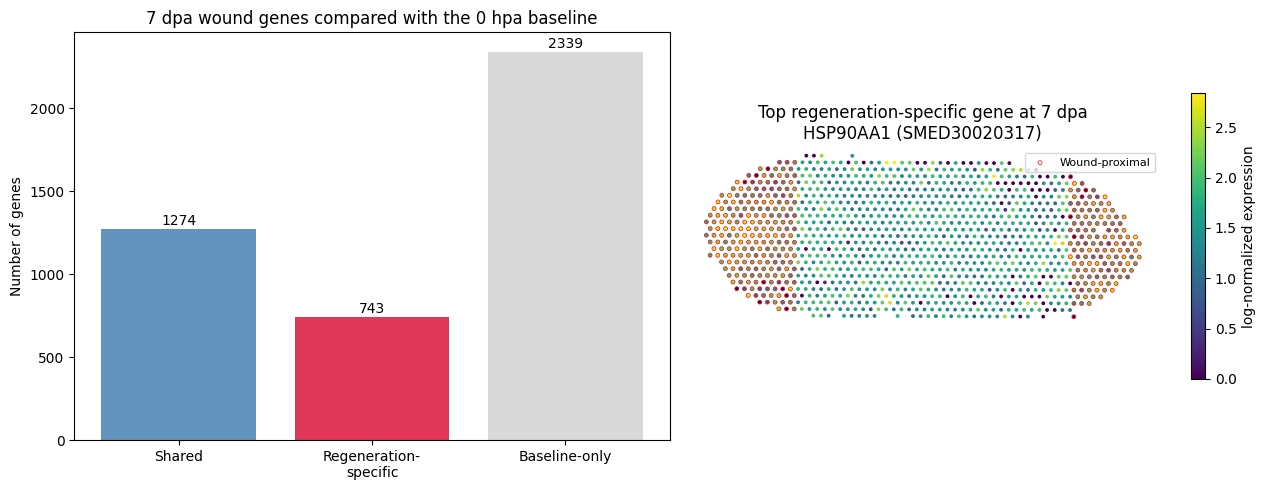

In [3]:
shared = degs_7d & degs_0h
regen_specific = degs_7d - degs_0h
baseline_only = degs_0h - degs_7d

print(f'Shared:                {len(shared)} ({len(shared) / len(degs_7d):.1%} of 7 dpa wound genes)')
print(f'Regeneration-specific: {len(regen_specific)} ({len(regen_specific) / len(degs_7d):.1%})')
print(f'Baseline-only:         {len(baseline_only)}')
print(f'Fraction of the 0 hpa signature regained at 7 dpa: {len(shared) / len(degs_0h):.1%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cats = ['Shared', 'Regeneration-\nspecific', 'Baseline-only']
counts = [len(shared), len(regen_specific), len(baseline_only)]
bars = axes[0].bar(cats, counts, color=['steelblue', 'crimson', 'lightgray'], alpha=0.85)
for bar, c in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(counts) * 0.01,
                 str(c), ha='center', fontsize=10)
axes[0].set_ylabel('Number of genes')
axes[0].set_title('7 dpa wound genes compared with the 0 hpa baseline')

ranked_regen = [g for g in res_7d['names'] if g in regen_specific and g in id2sym]
gid = ranked_regen[0]
gsym = id2sym[gid]
X = adata_7d[:, gid].X
expr = np.asarray(X.toarray() if sp.issparse(X) else X).flatten()
coords = adata_7d.obsm['spatial_scaled']
mask = adata_7d.obs['wound_proximal'].values
im = axes[1].scatter(coords[:, 0], coords[:, 1], c=expr, cmap='viridis', s=3,
                     vmin=0, vmax=np.percentile(expr, 99))
axes[1].scatter(coords[mask, 0], coords[mask, 1], edgecolors='red', facecolors='none',
                s=8, linewidths=0.5, label='Wound-proximal')
plt.colorbar(im, ax=axes[1], shrink=0.7, label='log-normalized expression')
axes[1].set_aspect('equal')
axes[1].axis('off')
axes[1].set_title(f'Top regeneration-specific gene at 7 dpa\n{gsym} ({gid})')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_deg_sets.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** - 2,017 genes mark the wound at 7 dpa and 3,613 at 0 hpa.
- 1,274 of the 7 dpa genes (63%) are shared with 0 hpa, and 743 (37%) are regeneration-specific.
- 2,339 baseline genes are not yet wound-enriched at 7 dpa, so only 35% of the 0 hpa signature has been regained.
- The top annotated regeneration-specific gene is HSP90AA1, a chaperone that helps fold newly made proteins and is typically high in cells with heavy protein synthesis.

## 3. Functional categories of each gene set

**What.** Test whether the shared and regeneration-specific genes are enriched for six curated categories: muscle, extracellular matrix (ECM), cell cycle, stem cell / PIWI / Wnt, wound healing / proteolysis, and neural.

**Why these categories.** They cover the programs that distinguish the two states: cell cycle, stem-cell, and wound-healing genes would point to regeneration still in progress, while neural genes would point to restored neural identity. Muscle and ECM capture structural tissue building.

**Test.** One-sided Fisher's exact test per category. Categories are defined by human gene symbols, so planarian genes are mapped through the BLAST table, and the background is all genes in the 7 dpa section with a human ortholog.

Background: 7095 annotated genes | shared: 923 | regeneration-specific: 521

Shared genes:
                   category  overlap  odds_ratio  p_value                                 genes
                     Muscle        6    2.685714 0.046123 ACTN2, MYH10, MYH6, MYL1, TNNI2, TPM3
       Extracellular matrix        1    0.477068 0.876650                                 LAMB1
                 Cell cycle        1    0.351239 0.938662                                CDC25C
     Stem cell / PIWI / Wnt        2    1.338111 0.475328                           AXIN1, TCF7
Wound healing / proteolysis        5    6.717865 0.005277          CTSB, CTSD, CTSL, MMP2, MMP9
                     Neural        3    2.871894 0.130840                     CHAT, SYP, TUBA1A

Regeneration-specific genes:
                   category  overlap  odds_ratio  p_value                                            genes
                     Muscle        8    7.870445 0.000069 ACTG1, ACTN1, MYH1, MYH7, MYL9, TNNI3, TPM

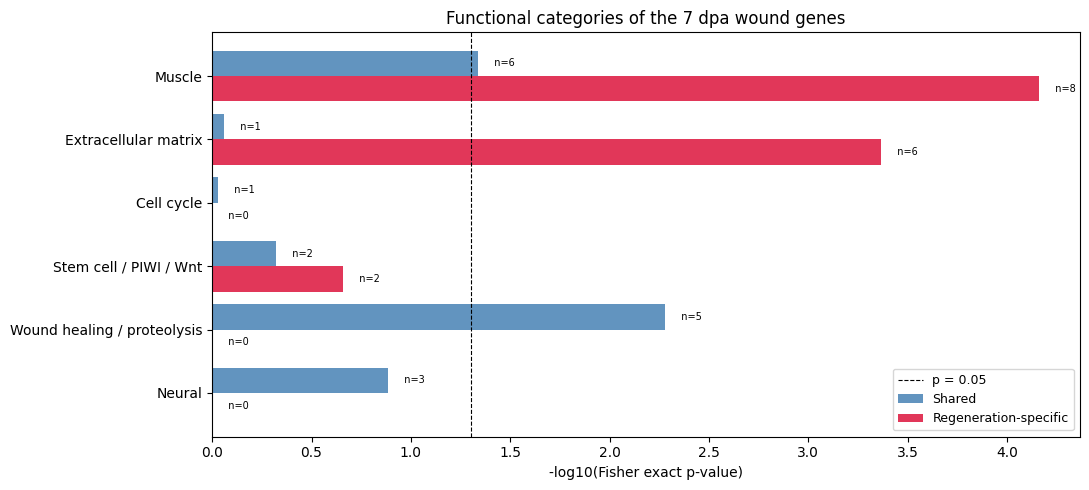

In [4]:
GENE_SETS = {
    'Muscle': [
        'MYOD1', 'MYOG', 'MYH1', 'MYH2', 'MYH3', 'MYH4', 'MYH6', 'MYH7',
        'MYH8', 'MYH9', 'MYH10', 'MYH11', 'MYL1', 'MYL2', 'MYL3', 'MYL4',
        'MYL6', 'MYL9', 'ACTA1', 'ACTA2', 'ACTC1', 'ACTG1', 'ACTG2',
        'ACTN1', 'ACTN2', 'ACTN3', 'TPM1', 'TPM2', 'TPM3', 'TPM4',
        'TNNT1', 'TNNT2', 'TNNT3', 'TNNI1', 'TNNI2', 'TNNI3', 'TNNC1',
        'CSRP3', 'DMD', 'DES', 'TTN',
    ],
    'Extracellular matrix': [
        'COL1A1', 'COL1A2', 'COL2A1', 'COL3A1', 'COL4A1', 'COL4A2',
        'COL4A3', 'COL4A4', 'COL4A5', 'COL5A1', 'COL5A2', 'COL6A1',
        'COL6A2', 'COL6A3', 'COL6A5', 'COL6A6', 'COL12A1', 'COL18A1',
        'FN1', 'LAMA1', 'LAMA2', 'LAMA3', 'LAMA4', 'LAMA5',
        'LAMB1', 'LAMB2', 'LAMB3', 'LAMC1', 'LAMC2', 'LAMC3',
        'FBN1', 'FBN2', 'NID1', 'NID2', 'HSPG2', 'BGN', 'DCN', 'LUM',
    ],
    'Cell cycle': [
        'MCM2', 'MCM3', 'MCM4', 'MCM5', 'MCM6', 'MCM7',
        'CDK1', 'CDK2', 'CDK4', 'CDK6', 'CCNB1', 'CCNB2',
        'CCNE1', 'CCNE2', 'CCND1', 'CCND2', 'CCNA2',
        'MKI67', 'TOP2A', 'PCNA', 'AURKA', 'AURKB', 'BIRC5', 'CDC20',
        'CDC25A', 'CDC25B', 'CDC25C', 'PLK1', 'BUB1', 'BUB1B', 'MAD2L1',
    ],
    'Stem cell / PIWI / Wnt': [
        'PIWIL1', 'PIWIL2', 'PIWIL3', 'PIWIL4', 'DDX4',
        'WNT1', 'WNT3A', 'WNT5A', 'WNT5B', 'WNT11', 'WNT16',
        'CTNNB1', 'AXIN1', 'AXIN2', 'LEF1', 'TCF7', 'TCF7L1', 'TCF7L2',
        'FZD1', 'FZD2', 'FZD7', 'DVL1', 'DVL2', 'DVL3',
        'SOX2', 'NANOG', 'POU5F1',
    ],
    'Wound healing / proteolysis': [
        'MMP1', 'MMP2', 'MMP3', 'MMP7', 'MMP9', 'MMP10', 'MMP11', 'MMP13',
        'MMP14', 'MMP15', 'MMP16', 'MMP17', 'TIMP1', 'TIMP2', 'TIMP3',
        'PLAU', 'PLAUR', 'PLG', 'SERPINE1', 'SERPINB2',
        'TGFB1', 'TGFB2', 'TGFB3', 'TGFBR1', 'TGFBR2',
        'CTSB', 'CTSD', 'CTSK', 'CTSL', 'CTSS',
    ],
    'Neural': [
        'NEFM', 'NEFL', 'NEFH', 'TUBB3', 'TUBA1A', 'MAPT',
        'SYP', 'SYN1', 'SNAP25', 'STX1A', 'STX1B', 'ELAVL3', 'ELAVL4',
        'SOX10', 'PAX6', 'GFAP', 'CHAT', 'TH',
    ],
}

universe = {id2sym[g].upper() for g in adata_7d.var_names if g in id2sym}


def to_symbols(smed_ids):
    return {id2sym[g].upper() for g in smed_ids if g in id2sym}


def enrich(hits):
    rows = []
    for name, genes in GENE_SETS.items():
        in_univ = {g.upper() for g in genes} & universe
        overlap = in_univ & hits
        a = len(overlap)
        b = len(hits) - a
        c = len(in_univ) - a
        d = len(universe) - len(hits) - c
        odds, p = (float('nan'), 1.0) if a == 0 else stats.fisher_exact([[a, b], [c, d]], alternative='greater')
        rows.append({'category': name, 'overlap': a, 'odds_ratio': odds, 'p_value': p,
                     'genes': ', '.join(sorted(overlap))})
    return pd.DataFrame(rows)


shared_sym, regen_sym = to_symbols(shared), to_symbols(regen_specific)
enrich_shared, enrich_regen = enrich(shared_sym), enrich(regen_sym)

print(f'Background: {len(universe)} annotated genes | shared: {len(shared_sym)} | '
      f'regeneration-specific: {len(regen_sym)}\n')
print('Shared genes:')
print(enrich_shared.to_string(index=False))
print('\nRegeneration-specific genes:')
print(enrich_regen.to_string(index=False))

cats = list(GENE_SETS)
nl_shared = -np.log10(enrich_shared['p_value'].astype(float).clip(lower=1e-30))
nl_regen = -np.log10(enrich_regen['p_value'].astype(float).clip(lower=1e-30))
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(cats))
w = 0.4
ax.barh(y - w / 2, nl_shared, w, color='steelblue', alpha=0.85, label='Shared')
ax.barh(y + w / 2, nl_regen, w, color='crimson', alpha=0.85, label='Regeneration-specific')
ax.axvline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8, label='p = 0.05')
for i in range(len(cats)):
    ax.text(nl_shared[i] + 0.05, y[i] - w / 2, f"  n={enrich_shared.iloc[i]['overlap']}", va='center', fontsize=7)
    ax.text(nl_regen[i] + 0.05, y[i] + w / 2, f"  n={enrich_regen.iloc[i]['overlap']}", va='center', fontsize=7)
ax.set_yticks(y)
ax.set_yticklabels(cats)
ax.invert_yaxis()
ax.set_xlabel('-log10(Fisher exact p-value)')
ax.set_title('Functional categories of the 7 dpa wound genes')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** - **Shared genes** are enriched for wound healing / proteolysis (5 genes: CTSB, CTSD, CTSL, MMP2, MMP9; p = 0.005), marginally for muscle (p = 0.046), and not for neural genes (p = 0.13).
- **Regeneration-specific genes** are strongly enriched for muscle (8 genes, p = 7 × 10⁻⁵) and ECM (6 genes, including COL1A2, COL4A2, LAMC1, NID2; p = 4 × 10⁻⁴). They contain no cell-cycle, wound-healing, or neural genes, and stem-cell genes are not enriched (PIWIL1 and TCF7; p = 0.22).

## 4. Interpretation

The 7 dpa wound fits neither state cleanly.

- **Not fully restored.** Only 35% of the baseline signature has been regained, and over a third of the 7 dpa wound genes are new.
- **Not an early-stage wound either.** The new genes contain no cell-cycle or wound-healing genes and are not enriched for stem-cell genes, so proliferation and wound closure have largely ended.
- **Structural tissue is still being built.** The new genes are dominated by muscle and ECM, and the top new gene is a chaperone associated with high protein synthesis. The wound is still assembling muscle and its supporting scaffold, not only neurons.
- **Neural identity is only partly there.** The shared genes are not enriched for the conserved mature-neuron markers in the neural category, even though cell2location (which uses a planarian-specific reference) assigns many neurons to these spots. One reading is that the new cells have taken on a planarian neural identity but do not yet express the conserved mature-neuron genes. The other is low power: the neural category has only 18 genes, and few of them have planarian orthologs. The same test does detect muscle and ECM enrichment, which argues somewhat against pure power loss, but the data cannot rule it out.
- **Caveat on the shared genes.** The head and tail ends express high levels of proteases in the intact animal, so the shared wound-healing enrichment likely reflects regional identity rather than ongoing repair.

At 7 dpa, the wound has been refilled with neurons in the right arrangement, but its gene expression has not yet caught up.

## Summary

**Across the project**

1. Neoblasts accumulate at the wound from 12 hpa to 3 dpa (notebook 02).
2. Neurons are the most dynamic differentiated cell type. They are lost at the wound early and are restored there by 7 dpa (notebook 03).
3. The spatial pattern at 7 dpa fits best with local production of new neurons that then sort into a compact cluster (notebook 04).
4. The rebuilt tissue is only partly mature: 35% of the baseline signature is regained, and muscle and ECM programs are still active (this notebook).

**Main conclusion:** spatial recovery comes before molecular recovery. By 7 dpa neurons are back in place, but the tissue is still maturing.

**Limitations**
- One section per timepoint and no biological replicates. All p-values reflect variation between spots within one section.
- Cell-type proportions are cell2location estimates, so any bias in that model carries into notebooks 02–04.
- At 0 hpa the wound regions are the intact head and tail ends. Using them as the baseline assumes these regions are comparable to the rebuilt tissue, which holds only in part.
- The gene categories are small, hand-curated lists, and planarian genes are mapped to human symbols by BLAST best hit, so genes without a human match are left out.

**Open questions**
- Timepoints between 3 and 7 dpa would show the neoblast-to-neuron transition directly.
- Timepoints after 7 dpa (for example 14 or 28 dpa) would show whether the remaining 65% of the baseline signature is eventually regained.